# Proper orthogonal decomposition and POD-Galerkin ROM: 1D viscous Burgers

*Companion notebook to Section 2.1 of [Machine learning for fluid dynamics](https://palzhanov.com/ml-fluids/02-fundamentals.html#pod-galerkin).*

We build a reduced-order model of the viscous Burgers equation

$$
\partial_t u + u\,\partial_x u = \nu\,\partial_{xx} u, \qquad x\in[0,1)\ \text{periodic},\ t\in(0,T],
$$

a one-dimensional model of nonlinear advection and diffusion. A bump riding on a uniform background flow is carried across the domain while its leading edge steepens into a front. Moving, sharpening features like this are exactly what makes model reduction of fluid flows hard.

Steps:
1. Solve the full-order model (FOM) with finite differences and collect snapshots.
2. Compute the POD basis with the SVD and look at singular value decay and modes.
3. Measure the best-approximation (projection) error as a function of the number of modes $N$.
4. Build the POD-Galerkin ROM, which inherits the quadratic structure of the equation, and compare it with the FOM.
5. Use the ROM at a viscosity not seen in training.
6. See how the singular value decay slows down when transport dominates (the Kolmogorov $n$-width barrier).

Only `numpy` and `matplotlib` are needed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Full-order model

Uniform periodic grid with $n$ points, second-order central differences, and the convective term in conservative form $\partial_x(u^2/2)$. The semi-discrete system is

$$
\dot{\mathbf u} = A\mathbf u + \mathbf n(\mathbf u), \qquad A = \nu D_2, \qquad \mathbf n(\mathbf u) = -\tfrac12 D_1(\mathbf u\circ\mathbf u),
$$

integrated with the classical fourth-order Runge–Kutta method. The initial condition is a Gaussian bump on a unit background velocity, $u_0(x) = 1 + \tfrac12\exp\!\big(-(x-0.25)^2/0.06^2\big)$, so the bump travels to the right at speed of about 1 to 1.5 while its front steepens and viscosity smooths it.

In [2]:
n = 256                      # grid points on the periodic domain [0, 1)
x = np.arange(n) / n
dx = 1.0 / n

# Periodic difference matrices (circulant)
I = np.eye(n)
P = np.roll(I, 1, axis=1)    # (P u)_i = u_{i+1}
D1 = (P - P.T) / (2 * dx)
D2 = (P - 2 * I + P.T) / dx**2

def u_init(x):
    return 1.0 + 0.5 * np.exp(-((x - 0.25) / 0.06) ** 2)

def rk4(rhs, u0, dt, n_steps, save_every):
    u = u0.copy()
    out = [u.copy()]
    for k in range(1, n_steps + 1):
        k1 = rhs(u); k2 = rhs(u + 0.5 * dt * k1)
        k3 = rhs(u + 0.5 * dt * k2); k4 = rhs(u + dt * k3)
        u = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if k % save_every == 0:
            out.append(u.copy())
    return np.array(out).T   # shape (space, time)

def solve_fom(nu, T=0.6, dt=1e-4, save_every=30):
    A = nu * D2
    rhs = lambda u: A @ u - 0.5 * D1 @ (u * u)
    n_steps = int(round(T / dt))
    U = rk4(rhs, u_init(x), dt, n_steps, save_every)
    t = np.linspace(0, T, U.shape[1])
    return t, U

nu = 0.005
tic = time.perf_counter()
t, S = solve_fom(nu)
fom_time = time.perf_counter() - tic
print(f"snapshot matrix S: {S.shape[0]} dofs x {S.shape[1]} snapshots, FOM time {fom_time:.2f} s")

snapshot matrix S: 256 dofs x 201 snapshots, FOM time 0.83 s


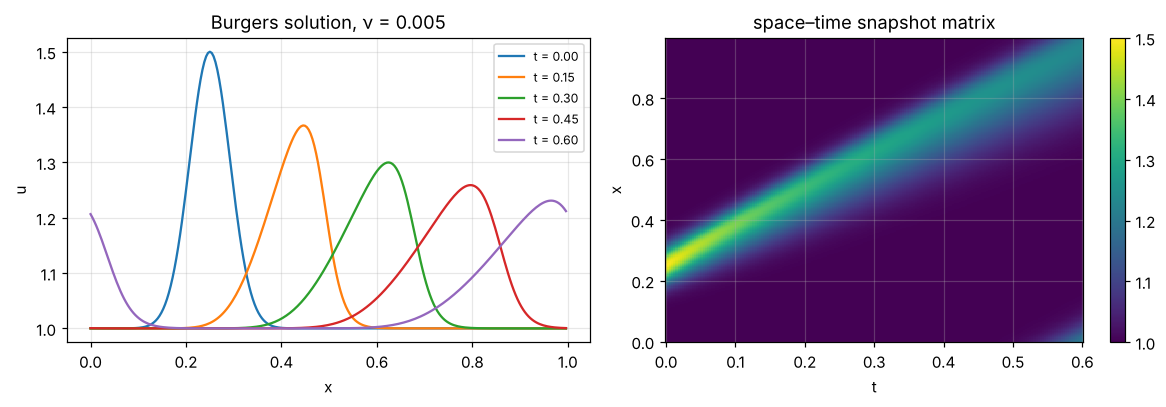

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k in range(0, S.shape[1], 50):
    axes[0].plot(x, S[:, k], label=f"t = {t[k]:.2f}")
axes[0].set(xlabel="x", ylabel="u", title=f"Burgers solution, ν = {nu}")
axes[0].legend(fontsize=8)
im = axes[1].pcolormesh(t, x, S, shading="auto", cmap="viridis")
axes[1].set(xlabel="t", ylabel="x", title="space–time snapshot matrix")
fig.colorbar(im, ax=axes[1])
plt.tight_layout()

### Animation of the full-order solution

The bump moves to the right with the background flow, its leading edge steepens, and viscosity slowly flattens it; it re-enters on the left because the domain is periodic. Use the player controls (play, pause, step, speed, loop) and the frame slider below. The player is JavaScript embedded in the output, so it works in Jupyter, Colab and nbviewer, but not in GitHub's static notebook preview.

In [4]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

frames = range(0, S.shape[1], 4)                 # every 4th snapshot keeps the notebook small
fig, ax = plt.subplots(figsize=(6.4, 3.2), dpi=72)
ax.plot(x, S[:, 0], color="0.75", lw=1, label="initial condition")
(line,) = ax.plot(x, S[:, 0], color="C0", lw=2, label="FOM")
title = ax.set_title(f"viscous Burgers, ν = {nu},  t = {t[0]:.3f}")
ax.set(xlabel="x", ylabel="u", xlim=(0, 1), ylim=(0.95, 1.55))
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()

def update(k):
    line.set_ydata(S[:, k])
    title.set_text(f"viscous Burgers, ν = {nu},  t = {t[k]:.3f}")
    return line, title

anim = FuncAnimation(fig, update, frames=frames, interval=80)
plt.close(fig)                                   # show only the interactive player
HTML(anim.to_jshtml(default_mode="loop"))

The same animation as a GIF, for viewers such as GitHub's notebook preview that do not run the player above.

GIF size: 218 kB


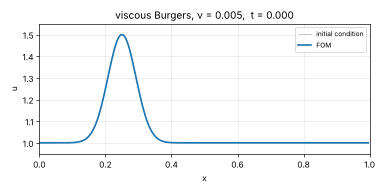

In [5]:
import tempfile
from matplotlib.animation import PillowWriter
from IPython.display import Image

with tempfile.TemporaryDirectory() as tmp:
    gif_path = f"{tmp}/burgers_fom.gif"
    anim.save(gif_path, writer=PillowWriter(fps=12), dpi=60)
    gif = open(gif_path, "rb").read()
print(f"GIF size: {len(gif) / 1024:.0f} kB")
Image(data=gif, format="gif")

## 2. POD via the singular value decomposition

Stack the snapshots as columns of $S\in\mathbb R^{n\times m}$ and compute $S = U\Sigma W^\top$. The first $N$ left singular vectors $V_N = U[:, :N]$ form the POD basis: among all $N$-dimensional subspaces, it minimizes the sum of squared projection errors of the snapshots,

$$
\sum_{j=1}^m \|\mathbf s_j - V_N V_N^\top \mathbf s_j\|_2^2 = \sum_{i>N} \sigma_i^2 .
$$

(We use the Euclidean inner product; on a non-uniform mesh one would weight it with the mass matrix. When $m \ll n$, Sirovich's *method of snapshots* computes the same basis from the small $m\times m$ correlation matrix $S^\top S$.)

N =  1: captured energy = 0.992670, 1 - energy = 7.3e-03
N =  5: captured energy = 0.999228, 1 - energy = 7.7e-04
N = 10: captured energy = 0.999953, 1 - energy = 4.7e-05
N = 20: captured energy = 1.000000, 1 - energy = 2.3e-07
N = 40: captured energy = 1.000000, 1 - energy = 5.4e-12


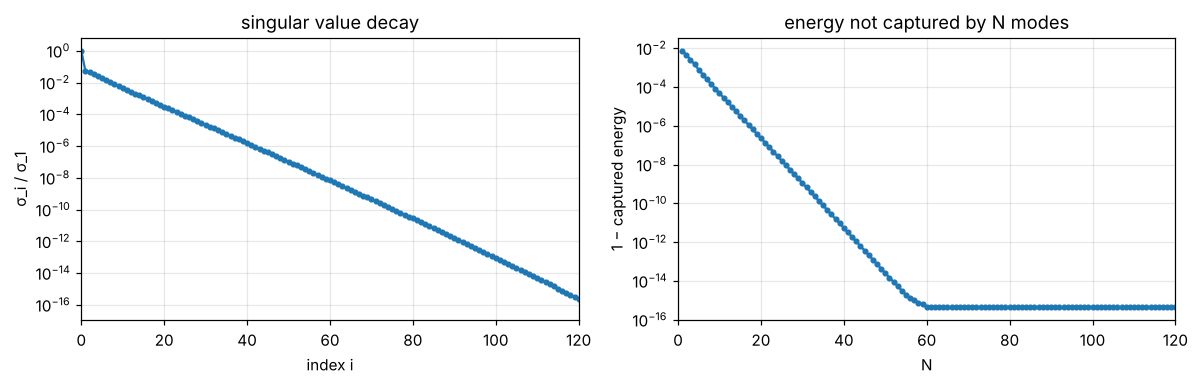

In [6]:
U_svd, sigma, Wt = np.linalg.svd(S, full_matrices=False)
energy = np.cumsum(sigma**2) / np.sum(sigma**2)

for N in (1, 5, 10, 20, 40):
    print(f"N = {N:2d}: captured energy = {energy[N-1]:.6f}, 1 - energy = {1-energy[N-1]:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(sigma / sigma[0], "o-", ms=3)
axes[0].set(xlabel="index i", ylabel="σ_i / σ_1", title="singular value decay", xlim=(0, 120))
axes[1].semilogy(np.arange(1, len(energy) + 1), 1 - energy + 1e-16, "o-", ms=3)
axes[1].set(xlabel="N", ylabel="1 − captured energy", title="energy not captured by N modes", xlim=(0, 120))
plt.tight_layout()

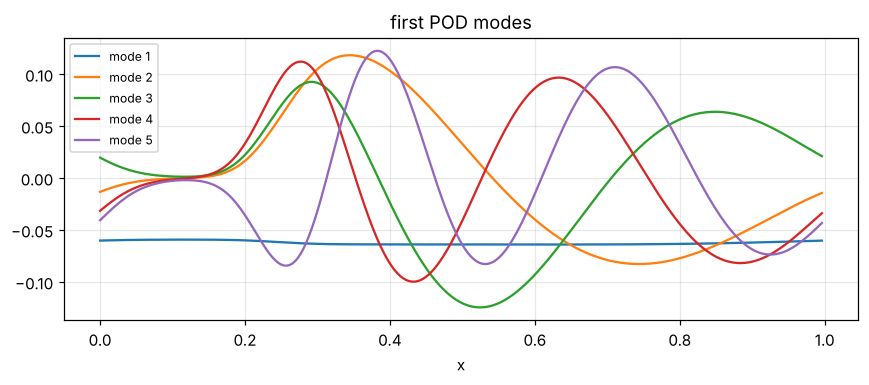

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i in range(5):
    ax.plot(x, U_svd[:, i], label=f"mode {i+1}")
ax.set(xlabel="x", title="first POD modes")
ax.legend(fontsize=8)
plt.tight_layout()

The first mode is essentially the uniform background flow. The others are global, wave-like patterns spread over the whole path of the bump, with more oscillations as the index grows. This is typical of transport: a feature that moves is represented by superposing many fixed modes with different phases, rather than by one mode that follows it.

## 3. Best-approximation error

Before building any dynamics, measure how well the subspace can represent the data at all: the relative projection error

$$
e_{\text{proj}}(N) = \frac{\|S - V_N V_N^\top S\|_F}{\|S\|_F}.
$$

No reduced model in this subspace can do better than this.

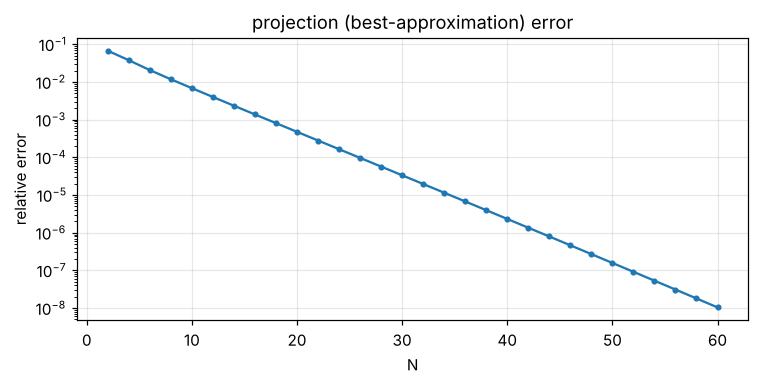

In [8]:
Ns = np.arange(2, 61, 2)
def proj_error(V, S):
    return np.linalg.norm(S - V @ (V.T @ S)) / np.linalg.norm(S)

e_proj = np.array([proj_error(U_svd[:, :N], S) for N in Ns])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(Ns, e_proj, "o-", ms=3)
ax.set(xlabel="N", ylabel="relative error", title="projection (best-approximation) error")
plt.tight_layout()

## 4. POD-Galerkin reduced-order model

Insert $\mathbf u \approx V_N \mathbf a(t)$ into the semi-discrete equations and project onto the basis (Galerkin: test with $V_N^\top$):

$$
\dot{\mathbf a} = \hat A\,\mathbf a + \hat H(\mathbf a\otimes\mathbf a), \qquad
\hat A = V_N^\top A V_N, \qquad
\hat H_{kij} = -\tfrac12\, \mathbf v_k^\top D_1(\mathbf v_i\circ\mathbf v_j).
$$

Because the nonlinearity is quadratic, $\hat A$ and the $N\times N\times N$ tensor $\hat H$ are computed once, offline. The online cost then depends only on $N$, not on $n$: no hyper-reduction is needed for this equation. The initial condition is projected, $\mathbf a(0)=V_N^\top\mathbf u_0$.

In [9]:
def build_rom(V, nu):
    A_hat = V.T @ (nu * D2) @ V
    # H_hat[k, i, j] = -1/2 v_k^T D1 (v_i * v_j)
    VV = V[:, :, None] * V[:, None, :]                    # (n, N, N)
    H_hat = -0.5 * np.einsum("nk,nm,mij->kij", V, D1, VV, optimize=True)
    return A_hat, H_hat

def solve_rom(V, nu, T=0.6, dt=1e-4, save_every=30):
    A_hat, H_hat = build_rom(V, nu)
    rhs = lambda a: A_hat @ a + np.einsum("kij,i,j->k", H_hat, a, a)
    a0 = V.T @ u_init(x)
    return rk4(rhs, a0, dt, int(round(T / dt)), save_every)   # (N, time)

N = 20
V = U_svd[:, :N]
tic = time.perf_counter()
A_rom = solve_rom(V, nu)
rom_time = time.perf_counter() - tic
S_rom = V @ A_rom
err = np.linalg.norm(S - S_rom) / np.linalg.norm(S)
print(f"N = {N}: relative ROM error {err:.2e} (projection error {proj_error(V, S):.2e})")
print(f"FOM {fom_time:.2f} s vs ROM {rom_time:.2f} s online")

N = 20: relative ROM error 5.30e-04 (projection error 4.78e-04)
FOM 0.83 s vs ROM 0.27 s online


The timing is only indicative. Here the FOM uses dense matrices and the ROM uses Python-level `einsum` calls in the time loop, so neither is optimized. The point is the scaling: the ROM cost per step is $O(N^3)$ regardless of $n$.

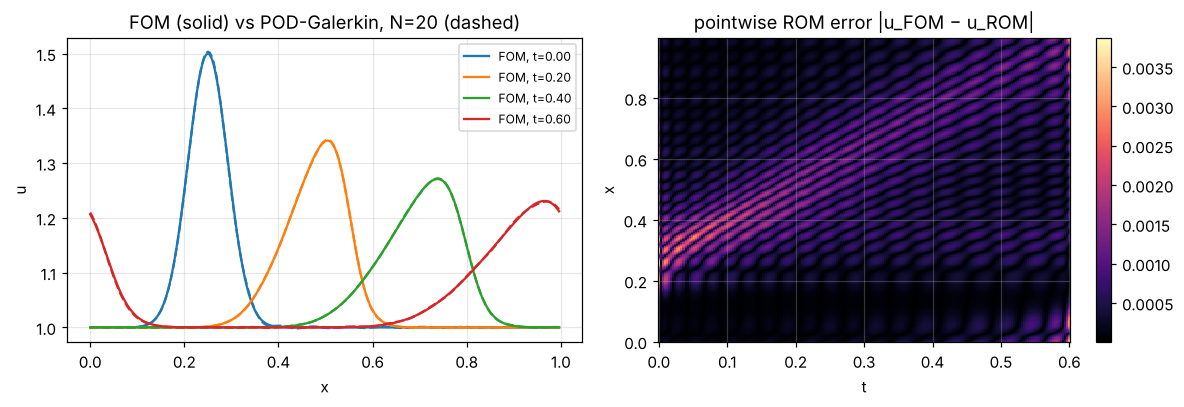

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, c in zip([0, 66, 133, 200], ["C0", "C1", "C2", "C3"]):
    axes[0].plot(x, S[:, k], c, label=f"FOM, t={t[k]:.2f}")
    axes[0].plot(x, S_rom[:, k], c + "--")
axes[0].set(xlabel="x", ylabel="u", title=f"FOM (solid) vs POD-Galerkin, N={N} (dashed)")
axes[0].legend(fontsize=8)
im = axes[1].pcolormesh(t, x, np.abs(S - S_rom), shading="auto", cmap="magma")
axes[1].set(xlabel="t", ylabel="x", title="pointwise ROM error |u_FOM − u_ROM|")
fig.colorbar(im, ax=axes[1])
plt.tight_layout()

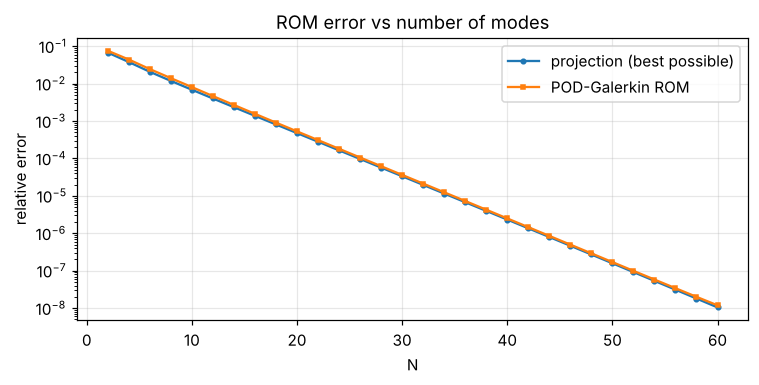

In [11]:
e_rom = []
for N in Ns:
    V = U_svd[:, :N]
    e_rom.append(np.linalg.norm(S - V @ solve_rom(V, nu)) / np.linalg.norm(S))
e_rom = np.array(e_rom)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(Ns, e_proj, "o-", ms=3, label="projection (best possible)")
ax.semilogy(Ns, e_rom, "s-", ms=3, label="POD-Galerkin ROM")
ax.set(xlabel="N", ylabel="relative error", title="ROM error vs number of modes")
ax.legend()
plt.tight_layout()

For this well-resolved, viscous problem the ROM error stays just above the projection error for every $N$: the Galerkin dynamics lose very little beyond what the subspace itself cannot represent. That is not guaranteed in general. For under-resolved or turbulent flows, the truncated modes carry the dissipation that keeps the dynamics bounded, and POD-Galerkin ROMs can drift or blow up; this is the classic motivation for stabilization and closure models.

## 5. A parametric ROM

So far the ROM only reproduces the simulation it was built from. A useful ROM must predict *new* parameters. Build one basis from snapshots at several viscosities, then run the ROM at a viscosity not in the training set.

In [12]:
nu_train = [0.005, 0.0075, 0.0125, 0.02]
S_train = np.hstack([solve_fom(v)[1] for v in nu_train])
U_p, sigma_p, _ = np.linalg.svd(S_train, full_matrices=False)

nu_test = 0.01
_, S_test = solve_fom(nu_test)

rows = []
for N in (10, 20, 30, 40, 60):
    V = U_p[:, :N]
    e_r = np.linalg.norm(S_test - V @ solve_rom(V, nu_test)) / np.linalg.norm(S_test)
    rows.append((N, proj_error(V, S_test), e_r))
print(" N   projection   ROM (ν = 0.01, unseen)")
for N, ep, er in rows:
    print(f"{N:2d}   {ep:.2e}     {er:.2e}")

 N   projection   ROM (ν = 0.01, unseen)
10   2.59e-03     3.04e-03
20   1.98e-04     2.34e-04
30   1.34e-05     1.68e-05
40   1.38e-06     1.68e-06
60   1.31e-08     1.45e-08


## 6. The transport problem: lower viscosity, slower decay

As $\nu$ decreases, the travelling bump stays sharper for longer. A sharp moving feature needs many global modes, so the singular values decay more slowly. This is the Kolmogorov $n$-width limitation of *linear* reduced spaces, and it is the main reason for the nonlinear-manifold and neural ROMs in Chapter 3 of the notes.

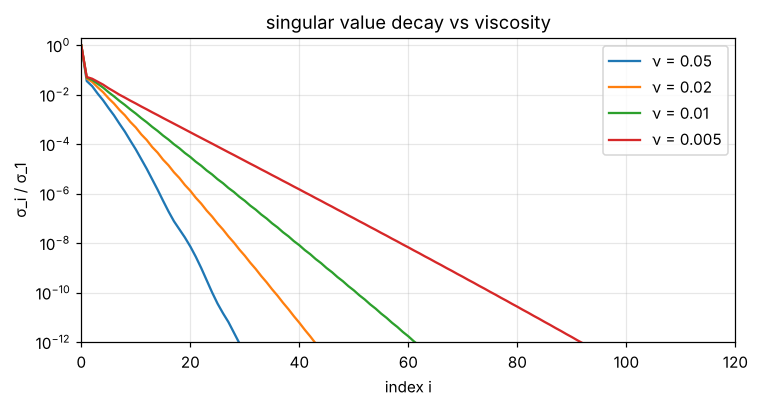

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for v in (0.05, 0.02, 0.01, 0.005):
    _, Sv = solve_fom(v)
    s = np.linalg.svd(Sv, compute_uv=False)
    ax.semilogy(s / s[0], label=f"ν = {v}")
ax.set(xlabel="index i", ylabel="σ_i / σ_1", title="singular value decay vs viscosity", xlim=(0, 120), ylim=(1e-12, 2))
ax.legend()
plt.tight_layout()

## Takeaways

- POD gives the optimal linear subspace for a given snapshot set; the singular values tell you how many modes you need.
- For polynomial nonlinearities, POD-Galerkin projection gives a ROM whose online cost is independent of the mesh size, with all reduced operators precomputed.
- The ROM error is bounded below by the projection error and is usually somewhat larger, since errors accumulate in time.
- A single basis can serve a range of parameters if trained on snapshots from that range.
- When transport dominates (small $\nu$), linear bases need many modes. This motivates hyper-reduction for general nonlinearities, closures for stability, and nonlinear (autoencoder or latent-dynamics) ROMs.

**Exercises.** (i) Subtract the snapshot mean before the SVD and compare. (ii) Replace Galerkin with least-squares Petrov–Galerkin. (iii) Fit the reduced operators from data instead of projecting them (operator inference, Section 2.3 of the notes) and compare with $\hat A,\hat H$.